# 2.0 Rigid-Body Motion in 3D

**ELEC3901 Robotic Manipulators, Lab 2** (week 2: Rigid Body Motion and Spatial Representation)

<br>

Read before this lab: the week 2 lecture and RVC3 Sections 2.2-2.4 (3D orientation and pose). Each section below follows the lecture slides listed next to it.

### Contents

| Section | Where | Time | Lecture slides |
|---|---|---|---|
| [2.1 Rotation matrices](#rot) | desk | 15 min | A rotation matrix is three axes; One point, three frames; SO(3): the constraints; Elementary rotations |
| [2.2 Composition order: fixed or body axes](#order) | desk | 10 min | Composition order: fixed or body axes; Worked example: x then y, both ways |
| [2.3 Roll-pitch-yaw angles](#rpy) | desk | 15 min | Euler and roll-pitch-yaw angles |
| [2.4 Pose in 3D: SE(3)](#pose) | desk | 20 min | From rotation to pose: why a 4 x 4?; Pose in 3D: SE(3); Worked example: the mat's pose as a 4 x 4 |
| [2.5 The work cell as a chain of frames](#chain) | desk | 10 min | The work cell as a chain of frames; What the camera tells you |
| [2.6 On the arm: three reference configurations](#refs) | arm | 15 min | - |
| [2.7 On the arm: the camera measures its own mount](#mount) | arm | 30 min | What the camera tells you |
| [2.8 The whole lab in spatialmath](#sm) | desk | 5 min | spatialmath in practice |

**How this notebook works.** Each section gives the maths from the lecture, a worked case in code, then the next case for you to
write: a *Task* (a function, checked against hidden values) or an *Exercise* (a few lines with `...` blanks, checked against the
toolbox by `try_it`, which prints `OK` or what looks wrong). Each section ends with the same result from `spatialmath`, the way you
will usually do it. *Desk* sections need no arm: do them before the session if you can. Sections marked *(stretch)* are for when
the core is done. A **Hint** opens when you click it - try without it first.

*Notation.* The lecture writes the pose of {M} relative to {B} as ${}^{B}\mathbf{T}_{M}$ (Corke, RVC3). In code it is `T_BM`: the
letters in the same order, so `T_BE @ T_EC` chains just as ${}^{B}\mathbf{T}_{E}\,{}^{E}\mathbf{T}_{C}$ does - the inner letters cancel.
Equations are numbered (1), (2), ... through the notebook; the code comments refer to them.

**Checkpoint for sign-off:** The checkpoint line from Section 2.7: your measured camera mount against the design value, and the spread of the T_BM estimates with each of the two mounts

Reference versions of previous weeks' tasks are imported from `omx_ref.py`, so last week never blocks this week; the functions you
write here are the ones your assignment will be built from.

> **Safety.** Keep the workspace clear of hands and cables before enabling torque, and set a conservative profile velocity
> (`arm.set_profile(60, 20)` or lower) before commanding motion. If anything unexpected happens, press the power isolator on the
> bench first, then think. Torque off (`arm.torque(False)`) before touching the arm.

The imports for this notebook. Section 2.6 connects to the arm; nothing before it needs the arm or the camera.

In [ ]:
import sys, os
# Repository layout: weekNN/ (notebooks), scripts/ (helper modules), data/ (your measurements, shared by every week).
for _up in ('.', '..', os.path.join('..', '..')):
    if os.path.isdir(os.path.join(_up, 'scripts')):
        _root = os.path.abspath(_up); sys.path.insert(0, os.path.join(_root, 'scripts'))
        os.makedirs(os.path.join(_root, 'data'), exist_ok=True); os.chdir(os.path.join(_root, 'data'))   # files save/load here
        break
import numpy as np, matplotlib.pyplot as plt, time, cv2
import roboticstoolbox as rtb
from spatialmath import SE3, SO3, SE2, UnitQuaternion
from spatialmath.base import trplot, tranimate
from omx_model import omx_robot, omx_ik, Q_LIM, T_EC, P_TIP_E, mount_tilt, look_down_pitch
from omx import OMX
from omx_camera import Camera, tip_in_mat, predicted_T_CM, pose_error
from omx_calib import small_T
from labcheck import check, try_it
NOM = dict(d1=0.0975, l2z=0.11315, l2x=0.0415, l3=0.162, l4=0.123)   # nominal link parameters (m)
from omx_ref import rot2, rot_about, se2, step_log, transform_point, transl2, trot2   # reference versions of PREVIOUS labs' tasks; your own definitions below override them
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline
omx = omx_robot()              # Robotics Toolbox model (nominal)
T_EC_CAD = T_EC   # the design camera mount (ROBOTIS CAD: optical axis 38 deg below the tool). Each arm's camera sits a little differently: Lab 2
                  # measures yours, and from Lab 3 on the MOUNT cell re-measures it every session and replaces T_EC
HOVER = 0.09      # tip hover height with the tool vertical: the OMX-F reaches r ~ 0.24 m there (touching the mat: r ~ 0.28 m)
CAM_HOVER = 0.15  # tip height for camera measurements, tool pitched with look_down_pitch(T_EC) so the camera looks straight down:
                  # the camera is then ~180 mm up, enough to see the marker ring around the clear zone

<br>

<a id='rot'></a>

### 2.1 Rotation matrices (desk)
---

A rotation matrix is three axes: the columns of ${}^{A}\mathbf{R}_{B}$ are the unit vectors $\hat{x}_B, \hat{y}_B, \hat{z}_B$ of {B},
written in {A}. It changes the frame a vector is written in:

$$ {}^{A}\mathbf{p} = {}^{A}\mathbf{R}_{B}\,{}^{B}\mathbf{p} \qquad (1) $$

Not every 3 x 3 matrix is a rotation. The columns must be unit length and mutually perpendicular, and the frame must stay right-handed:

$$ \mathbf{R}^{T}\mathbf{R} = \mathbf{I}, \qquad \det \mathbf{R} = +1 \qquad (2) $$

These matrices form the group SO(3). Turning about one axis gives an *elementary rotation*. About z, with $c = \cos\theta$ and
$s = \sin\theta$:

$$ \mathbf{R}_z(\theta) = \begin{bmatrix} c & -s & 0 \\ s & c & 0 \\ 0 & 0 & 1 \end{bmatrix} \qquad (3) $$

Column 1 is where $\hat{x}$ goes, $(c, s, 0)$; column 2 is where $\hat{y}$ goes, $(-s, c, 0)$; $\hat{z}$ is the axis and does not move.
$\mathbf{R}_x(\theta)$ and $\mathbf{R}_y(\theta)$ follow the same pattern, about their own axes.

#### Task 1a — Rotations in 3D and roll-pitch-yaw angles: elementary rotations
`rotz` is written for you: read it column by column against equation (3). Write `rotx` and `roty` the same way - each column is where
that axis goes. Watch the sign of the sines in `roty`: the y axis is the odd one out of the three.

In [ ]:
def rotx(a):
    """3x3 rotation about x by a (rad)."""
    # TODO: write your implementation here
    raise NotImplementedError

def roty(a):
    """3x3 rotation about y by a (rad)."""
    # TODO: write your implementation here
    raise NotImplementedError

def rotz(a):
    """3x3 rotation about z by a (rad). GIVEN - the worked example: the columns are where x and y go, z stays put."""
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0],      # column 0: x turns to (cos a, sin a, 0)
                     [s, c, 0],       # column 1: y turns to (-sin a, cos a, 0)
                     [0, 0, 1]])      # column 2: z is the axis - it does not move


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('rotx(0.3)', lambda: rotx(0.3), '93c9a91fee', decimals=6)
check('roty(-1.2)', lambda: roty(-1.2), 'a21c3048d4', decimals=6)
check('roty(0.5) @ rotx(0.3)', lambda: roty(0.5) @ rotx(0.3), '5809bde99f', decimals=6)

<details><summary><b>Hint</b></summary>

For `roty`, turn $\hat{z}$ towards $\hat{x}$: a positive rotation about y takes $\hat{z}$ to $(s, 0, c)$ and $\hat{x}$ to $(c, 0, -s)$.
So the minus sign sits below the diagonal (row 3, column 1), where $\mathbf{R}_x$ and $\mathbf{R}_z$ have it above.

</details>

**With spatialmath.** `SO3` objects hold the same matrices and keep them valid; `.A` is the NumPy array.

In [ ]:
# your elementary rotations against the toolbox
try_it('rotx(30 deg)', lambda: rotx(np.radians(30)), SO3.Rx(30, 'deg').A)
try_it('roty(30 deg)', lambda: roty(np.radians(30)), SO3.Ry(30, 'deg').A)
try_it('rotz(30 deg)', lambda: rotz(np.radians(30)), SO3.Rz(30, 'deg').A)

# an SO3 object prints as a matrix and composes with *
R = SO3.Rz(30, 'deg') * SO3.Ry(-45, 'deg')
print(R)
print('R R^T =\n', (R * R.inv()).A, '\ndet R =', np.linalg.det(R.A))

**Changing the reference frame.** The lecture's example (Lynch and Park, Section 3.2.1): three frames share an origin. {B} is {A}
turned 90 degrees about $\hat{z}_A$; {C} is {B} turned -90 degrees about $\hat{y}_B$. Rotations chain like the poses later on - the
inner letters cancel, ${}^{A}\mathbf{R}_{C} = {}^{A}\mathbf{R}_{B}\,{}^{B}\mathbf{R}_{C}$ - and equation (1) moves the point
${}^{C}\mathbf{p} = (0, -1, -1)$ into {A}.

In [ ]:
# --- Exercise 2.1: one point, three frames (the lecture's example) --------------------------------------------------
R_AB = ...                         # {B} is {A} turned 90 deg about z_A (your rotz)
R_BC = ...                         # {C} is {B} turned -90 deg about y_B (your roty)
R_AC = ...                         # chain them: inner letters cancel
p_A = ...                          # the point p_C = (0, -1, -1) written in {A}, equation (1)
try_it('A_R_C', R_AC, (SO3.Rz(90, 'deg') * SO3.Ry(-90, 'deg')).A)
try_it('A_p', p_A, [1, 1, 0])

**Is it a rotation?** Equation (2) is a test you can code. The lecture's three cases: a rotation, a mirror and a shear.

In [ ]:
# --- Exercise 2.1b: is it a rotation? ------------------------------------------------------------------------------
def is_rotation(R, tol=1e-9):
    ...                            # return True or False, from equation (2)

Rz90 = rotz(np.pi / 2)
mirror = np.diag([1.0, 1.0, -1.0])
shear = np.array([[1, 0.5, 0], [0, 1, 0], [0, 0, 1.0]])
try_it('Rz(90), a mirror, a shear', lambda: [is_rotation(Rz90), is_rotation(mirror), is_rotation(shear)], [True, False, False])

<details><summary><b>Hint</b></summary>

`np.allclose(R.T @ R, np.eye(3), atol=tol)` tests the columns; `np.linalg.det(R)` tests the handedness. The mirror passes the first
test and fails the second - which is why equation (2) needs both.

</details>

<br>

<a id='order'></a>

### 2.2 Composition order: fixed or body axes (desk)
---

Two rotations in turn can be about the **fixed** axes of the starting frame, or about the body's own **new** axes. With $\mathbf{R}_1$
first and $\mathbf{R}_2$ second:

$$ \text{fixed axes: } \mathbf{R} = \mathbf{R}_2\,\mathbf{R}_1, \qquad \text{body axes: } \mathbf{R} = \mathbf{R}_1\,\mathbf{R}_2 \qquad (4) $$

About the fixed axes each new rotation goes on the left; about the body axes, on the right. The columns of the product are where the
body axes end up.

In [ ]:
# --- worked case: 90 deg about z, then 90 deg about x - both ways, equation (4) -------------------------------------
Rz90, Rx90 = rotz(np.pi / 2), SO3.Rx(90, 'deg').A  # the given rotz, and the toolbox's R_x (yours works the same)
R_fixed_zx = Rx90 @ Rz90           # about the FIXED x: the second rotation goes on the left
R_body_zx = Rz90 @ Rx90            # about the NEW x: on the right
print('fixed axes:\n', np.round(R_fixed_zx, 3))
print('body axes:\n', np.round(R_body_zx, 3))
print('the body x axis ends up along', np.round(R_fixed_zx[:, 0], 3), '(fixed) and', np.round(R_body_zx[:, 0], 3), '(body)')

**Your turn: the lecture's case, 90 degrees about x, then 90 degrees about y.** Predict first, with your right hand: where does the body
x axis point at the end, each way? Write the two unit vectors, run the cell, then compute them in the next exercise.

In [ ]:
# --- Exercise 2.2a: predict ------------------------------------------------------------------------------------------
x_b_fixed_guess = ...              # e.g. [1, 0, 0]: where x_b ends up, rotations about the fixed axes
x_b_body_guess = ...               # the same, about the body (new) axes
try_it('your prediction, fixed axes', x_b_fixed_guess, (SO3.Ry(90, 'deg') * SO3.Rx(90, 'deg')).A[:, 0])
try_it('your prediction, body axes', x_b_body_guess, (SO3.Rx(90, 'deg') * SO3.Ry(90, 'deg')).A[:, 0])

In [ ]:
# --- Exercise 2.2b: compute it, equation (4) -------------------------------------------------------------------------
R_fixed = ...                      # 90 deg about x, then 90 deg about the fixed y
R_body = ...                       # 90 deg about x, then 90 deg about the new y
x_b_fixed = ...                    # where the body x axis ends up, fixed axes (one column of R_fixed)
try_it('fixed axes', R_fixed, (SO3.Ry(90, 'deg') * SO3.Rx(90, 'deg')).A)
try_it('body axes', R_body, (SO3.Rx(90, 'deg') * SO3.Ry(90, 'deg')).A)
try_it('the body x axis (fixed axes)', x_b_fixed, (SO3.Ry(90, 'deg') * SO3.Rx(90, 'deg')).A[:, 0])

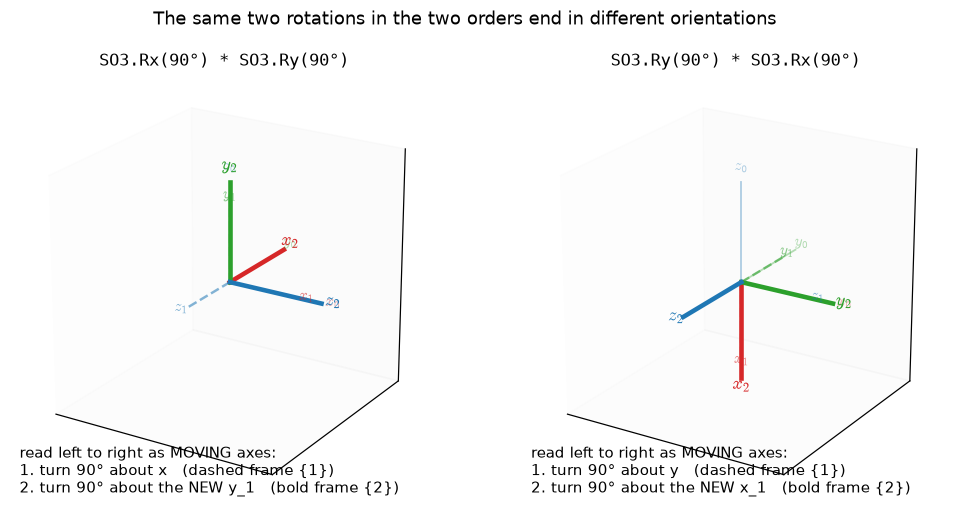

*What you just computed. The same two 90 degree rotations in the two orders end in different orientations. Read
    each product left to right as **moving** axes: turn about x, then about the *new* y (left), or about y, then the *new* x (right). The
    faint frame is the start, the dashed frame is after the first turn.*

<br>

<a id='rpy'></a>

### 2.3 Roll-pitch-yaw angles (desk)
---

Three angles describe any orientation. The toolbox's default, and ours, is roll-pitch-yaw in the **zyx** order:

$$ \mathbf{R} = \mathbf{R}_z(\text{yaw})\,\mathbf{R}_y(\text{pitch})\,\mathbf{R}_x(\text{roll}) \qquad (5) $$

The name lists the matrices as written. Read about the fixed axes, the right-hand factor acts first (equation (4)), so the turns go
roll about x, pitch about y, then yaw about z. The angles come back from the elements $r_{ij}$ of $\mathbf{R}$ (row $i$, column $j$,
counting from 1 as in the lecture; `R[i-1, j-1]` in code), for $|\text{pitch}| < 90°$:

$$ \text{pitch} = \operatorname{atan2}\!\left(-r_{31}, \sqrt{r_{11}^2 + r_{21}^2}\right), \quad
   \text{roll} = \operatorname{atan2}(r_{32}, r_{33}), \quad \text{yaw} = \operatorname{atan2}(r_{21}, r_{11}) \qquad (6) $$

Always state the convention: books and libraries differ.

In [ ]:
# --- worked case: a pure pitch of 30 deg - equation (6) gives the angles back ------------------------------------------
R = SO3.Ry(30, 'deg').A
pitch = np.arctan2(-R[2, 0], np.hypot(R[0, 0], R[1, 0]))     # r31 is R[2, 0]
roll = np.arctan2(R[2, 1], R[2, 2]); yaw = np.arctan2(R[1, 0], R[0, 0])
print('roll, pitch, yaw (deg):', np.round(np.degrees([roll, pitch, yaw]), 6))

#### Task 1b — Rotations in 3D and roll-pitch-yaw angles: roll-pitch-yaw angles
`rpy_to_R(roll, pitch, yaw)` returns equation (5), `R = Rz(yaw) @ Ry(pitch) @ Rx(roll)`, from your functions above. `R_to_rpy(R)` gets
`[roll, pitch, yaw]` back with equation (6), `arctan2` throughout. Assume |pitch| < 90 deg.

In [ ]:
def rpy_to_R(roll, pitch, yaw):
    """zyx roll-pitch-yaw (rad) -> 3x3 rotation matrix."""
    # TODO: write your implementation here
    raise NotImplementedError

def R_to_rpy(R):
    """3x3 rotation matrix -> [roll, pitch, yaw] (rad), zyx convention. Assume |pitch| < 90 deg."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('rpy_to_R(20, 30, 40 deg)', lambda: rpy_to_R(*np.radians([20, 30, 40])), '366fdc0aad', decimals=5)
check('orthonormal: R R^T', lambda: rpy_to_R(0.3, -1.1, 2.0) @ rpy_to_R(0.3, -1.1, 2.0).T, '51ad9d3fcd', decimals=6)
check('det = +1', lambda: np.linalg.det(rpy_to_R(0.3, -1.1, 2.0)), '3eafb06982', decimals=6)
check('round trip (20, 30, 40 deg)', lambda: R_to_rpy(rpy_to_R(*np.radians([20, 30, 40]))), 'f045d9e8a9', decimals=5)
check('round trip (-50, 10, 120 deg)', lambda: R_to_rpy(rpy_to_R(*np.radians([-50, 10, 120]))), '1863031f3d', decimals=5)

**With spatialmath.** `SO3.RPY(..., order='zyx')` builds equation (5); `.rpy(order='zyx')` is equation (6).

In [ ]:
# your functions against the toolbox
R_tb = SO3.RPY(np.radians([20, 30, 40]), order='zyx')
try_it('rpy_to_R(20, 30, 40 deg) against SO3.RPY', lambda: rpy_to_R(*np.radians([20, 30, 40])), R_tb.A)
try_it('R_to_rpy back to the angles', lambda: R_to_rpy(R_tb.A), R_tb.rpy(order='zyx'))

In [ ]:
# --- Exercise 2.3 (stretch): the round trip over many orientations --------------------------------------------------
rng = np.random.default_rng(1)
angles = rng.uniform([-3.1, -1.5, -3.1], [3.1, 1.5, 3.1], size=(100, 3))   # roll, pitch, yaw (rad); |pitch| < 86 deg
worst = ...                        # the largest |R_to_rpy(rpy_to_R(roll, pitch, yaw)) - [roll, pitch, yaw]| over all 100, rad
try_it('worst round-trip error (rad)', worst, 0.0, tol=1e-9)

<br>

<a id='pose'></a>

### 2.4 Pose in 3D: SE(3) (desk)
---

A pose in 3D is a rotation and a translation together, a 4 x 4 homogeneous transform - Lab 1's 3 x 3 one dimension up. The columns of
$\mathbf{R}$ are {A}'s axes in {B}, $\mathbf{t}$ is {A}'s origin in {B}, and a point gets a 1 appended so that one product does both:

$$ {}^{B}\mathbf{T}_{A} = \begin{bmatrix} \mathbf{R} & \mathbf{t} \\ \mathbf{0}^{T} & 1 \end{bmatrix}, \qquad
   \begin{bmatrix} {}^{B}\mathbf{p} \\ 1 \end{bmatrix} = {}^{B}\mathbf{T}_{A} \begin{bmatrix} {}^{A}\mathbf{p} \\ 1 \end{bmatrix} \qquad (7) $$

Poses chain by multiplying, ${}^{B}\mathbf{T}_{C} = {}^{B}\mathbf{T}_{A}\,{}^{A}\mathbf{T}_{C}$. Because $\mathbf{R}$ is orthonormal, the inverse
needs no general matrix inverse:

$$ {}^{A}\mathbf{T}_{B} = \left({}^{B}\mathbf{T}_{A}\right)^{-1} = \begin{bmatrix} \mathbf{R}^{T} & -\mathbf{R}^{T}\mathbf{t} \\ \mathbf{0}^{T} & 1 \end{bmatrix} \qquad (8) $$

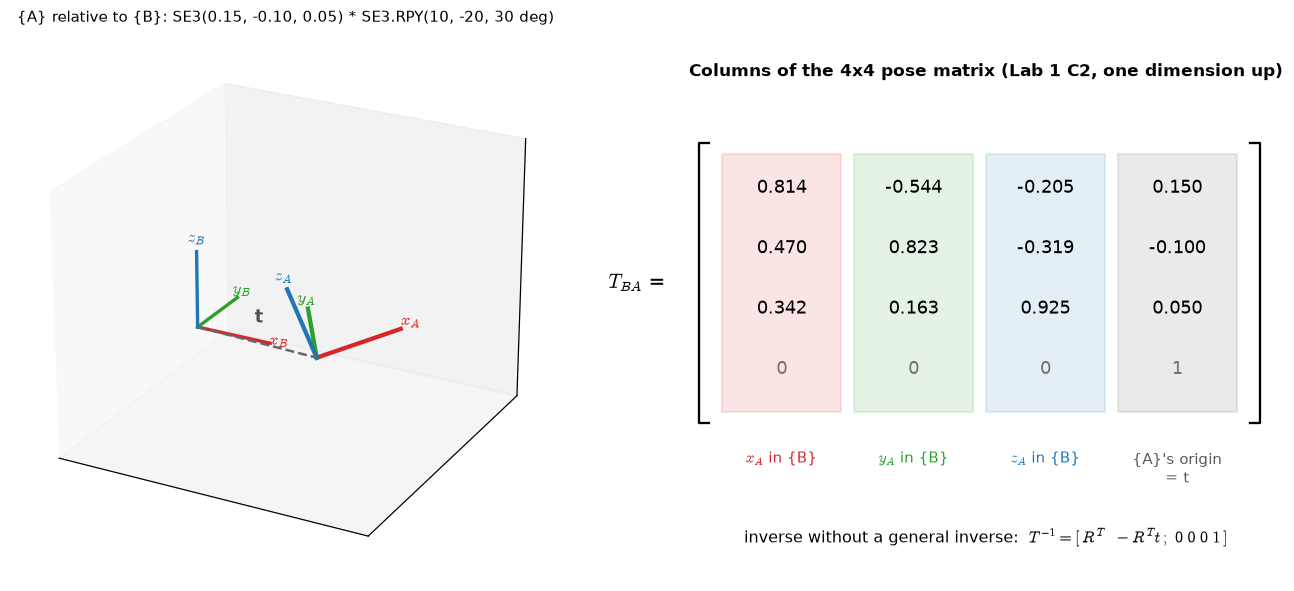

*A frame {A} relative to {B} in 3D, and its 4x4 matrix: the first three columns are {A}'s x, y and z axes written
    in {B}, the fourth is {A}'s origin **t** - Lab 1's picture one dimension up. Because R is orthonormal, the inverse comes from the
    transpose, equation (8).*

### Task 2 — Pose in 3D: build, invert and apply a transform
The 3D version of Lab 1's `se2`, one dimension up. Write `make_T(R, t)` - the 4x4 homogeneous transform with rotation `R` (3x3) and
translation `t` (3,) -, `inv_T(T)` - its inverse **from the transpose** (`R^T`, `-R^T t`), not `np.linalg.inv` - and
`transform_points(T, P)`, which maps points `P` (one point (3,) or `N x 3`) through `T` and returns the same shape.

In [ ]:
def make_T(R, t):
    """3x3 rotation, 3-vector -> 4x4 homogeneous transform."""
    # TODO: write your implementation here
    raise NotImplementedError

def inv_T(T):
    """Inverse of a 4x4 homogeneous transform, from R^T and -R^T t (no general matrix inverse)."""
    # TODO: write your implementation here
    raise NotImplementedError

def transform_points(T, P):
    """Map point(s) P ((3,) or N x 3) through the 4x4 transform T; returns the same shape."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
try:
    _R22 = small_T(np.array([0.3, -0.5, 0.8, 0, 0, 0]))[:3, :3]                      # independent of your rotx/roty/rotz
    _T22 = small_T(np.array([-0.4, 0.2, 1.1, 0.12, 0.03, -0.07]))
except NotImplementedError:
    print('  (test fixtures need your earlier function first)')
check('make_T of a rotation and a translation', lambda: make_T(_R22, [0.10, -0.20, 0.30]), '4a58135f9d', decimals=5)
check('inv_T(T) @ T is the identity', lambda: inv_T(make_T(_R22, [0.10, -0.20, 0.30])) @ make_T(_R22, [0.10, -0.20, 0.30]), '0b5daec8bb', decimals=6)
check('inv_T of another pose', lambda: inv_T(_T22), 'bb6d90fce9', decimals=6)
check('two points mapped through T', lambda: transform_points(_T22, [[0.05, 0.0, 0.0], [0.0, 0.10, 0.20]]), '45d826ec90', decimals=5)
check('one point keeps its shape', lambda: transform_points(_T22, [0.05, 0.0, 0.0]), '1d6b350db2', decimals=5)

**With spatialmath.** `SE3` composes with `*`, inverts with `.inv()` and applies itself to points with `*`.

In [ ]:
# your functions against the toolbox
T = SE3(0.10, -0.20, 0.30) * SE3.RPY(np.radians([20, 30, 40]), order='zyx')
try_it('make_T', lambda: make_T(T.R, T.t), T.A)
try_it('inv_T', lambda: inv_T(T.A), T.inv().A)
try_it('transform_points', lambda: transform_points(T.A, [0.05, 0.0, 0.0]), (T * [0.05, 0.0, 0.0]).ravel())

**The lecture's worked example: the mat's pose as a 4 x 4.** The mat is laid on the bench turned 5 degrees and 10 mm forward:
${}^{B}\mathbf{T}_{M}$ has $\mathbf{R}_z(5°)$ and $\mathbf{t} = (10, 0, 0)$ mm. The print fixes marker 24 at
${}^{M}\mathbf{T}_{24} = [\mathbf{I}, (0.25, 0.08, 0)]$, so ${}^{B}\mathbf{T}_{24} = {}^{B}\mathbf{T}_{M}\,{}^{M}\mathbf{T}_{24}$.

In [ ]:
# --- worked case (the lecture): where is marker 24 on the laid mat? ------------------------------------------------
T_BM_laid = np.eye(4)                                       # B_T_M, equation (7) by hand:
T_BM_laid[:3, :3] = rotz(np.radians(5))                     #   the mat's axes in {B} (turned 5 deg)
T_BM_laid[:3, 3] = [0.010, 0, 0]                            #   its origin in {B} (10 mm forward)
T_M24 = np.eye(4); T_M24[:3, 3] = [0.25, 0.08, 0]           # M_T_24: fixed by the print
T_B24 = T_BM_laid @ T_M24                                   # B_T_M M_T_24 = B_T_24: the inner letters cancel
print('marker 24 in {B} (mm):', np.round(1e3 * T_B24[:3, 3], 1), '  (the lecture: 252.1, 101.5, 0)')

In [ ]:
# the centre of marker 7 on the mat, from the print (used from here on)
from omx_camera import load_mat
_, corners_M = load_mat(scale=1.0)             # marker id -> its 4 corners in the mat frame (m), as printed
p_M7 = corners_M[7].mean(axis=0)
T_M7 = np.eye(4); T_M7[:3, 3] = p_M7           # its pose on the mat: axes along the mat's, origin at its centre
print('marker 7 on the mat (m):', np.round(p_M7, 4))

In [ ]:
# --- Exercise 2.4: your turn - marker 7 on the same laid mat, and back -----------------------------------------------
p_B7 = ...                         # marker 7 in the base frame: T_BM_laid applied to p_M7 (your transform_points)
p_M7_back = ...                    # and back into the mat frame, with your inv_T
moved_mm = ...                     # how far marker 7 moved when the mat was laid off, mm
try_it('marker 7 in {B}', p_B7, (SE3(0.010, 0, 0) * SE3.Rz(5, 'deg')) * p_M7)
try_it('and back', p_M7_back, p_M7)
try_it('how far it moved (mm)', moved_mm, 1e3 * np.linalg.norm(((SE3(0.010, 0, 0) * SE3.Rz(5, 'deg')) * p_M7).ravel() - p_M7), tol=1e-3)

**A chain by hand.** At home the kinematics gives the tool pose, the design gives the camera mount, and the camera measures marker 7.
Chain the three to find marker 7 in the base frame - it should land where the print puts it.

In [ ]:
# --- Exercise 2.4b: a chain by hand ---------------------------------------------------------------------------------
# The arm is at home. The kinematics gives the tool:  B_T_E: R = roty(30 deg) (tool pitched 30 deg down), t = (0.1913, 0, 0.1285) m.
# The design camera mount:                            E_T_C below (x_C = -y_E, optical axis 38 deg below the tool).
# The camera measures marker 7:                       C_T_7 below.
R_EC = np.array([[0, -0.6157, 0.7880], [-1, 0, 0], [0, -0.7880, -0.6157]]); t_EC = [-0.0459, 0.0, 0.0332]
T_C7 = np.array([[0, -1, 0, 0.1200], [-0.9272, 0, -0.3746, 0.1029], [0.3746, 0, -0.9272, 0.1528], [0, 0, 0, 1]])
T_BE = ...                         # use your make_T
T_EC_num = ...                     # use your make_T
T_B7 = ...                         # base <- tool <- camera <- marker 7
T_EB = ...                         # the inverse of T_BE, with your inv_T
try_it('B_T_7 against SE3', T_B7, (SE3(0.1913, 0, 0.1285) * SE3.Ry(30, 'deg')).A @ np.r_[np.c_[R_EC, t_EC], [[0, 0, 0, 1]]] @ T_C7, tol=1e-4)
try_it('marker 7 is where the mat says it is (m)', lambda: T_B7[:3, 3], [0.13, -0.12, 0.0], tol=2e-3)
try_it('E_T_B against SE3.inv()', T_EB, (SE3(0.1913, 0, 0.1285) * SE3.Ry(30, 'deg')).inv().A, tol=1e-4)

<details><summary><b>Hint</b></summary>

Write the chain with the letters first: ${}^{B}\mathbf{T}_{7} = {}^{B}\mathbf{T}_{E}\,{}^{E}\mathbf{T}_{C}\,{}^{C}\mathbf{T}_{7}$ - each inner pair
cancels. In code the names do the same: `T_BE @ T_EC_num @ T_C7`.

</details>

In [ ]:
# --- Exercise 2.4c (stretch): order in 3D ---------------------------------------------------------------------------
Rz90 = SE3.Rz(90, 'deg').A; Tx = SE3(0.1, 0, 0).A      # given as 4x4 arrays
origin_rot_then_move = ...         # the origin of Rz90 @ Tx
origin_move_then_rot = ...         # the origin of Tx @ Rz90
try_it('Rz90 @ Tx', origin_rot_then_move, (SE3.Rz(90, 'deg') * SE3(0.1, 0, 0)).t)
try_it('Tx @ Rz90', origin_move_then_rot, (SE3(0.1, 0, 0) * SE3.Rz(90, 'deg')).t)

<br>

<a id='chain'></a>

### 2.5 The work cell as a chain of frames (desk)
---

Every number in this course is a pose between two frames in one graph: the room {W}, the base {B}, the mat {M} (nominally {B} itself),
the end effector {E}, the wrist camera {C} and a marker on the mat - here marker 7. The camera never sees the base, or even the mat as a
whole: it measures a marker, ${}^{C}\mathbf{T}_{7}$, and the print fixes the marker's place on the mat, ${}^{M}\mathbf{T}_{7}$. Walking the
graph from the camera to the marker predicts what the camera should see:

$$ {}^{C}\mathbf{T}_{7} = \left({}^{B}\mathbf{T}_{E}(q)\,{}^{E}\mathbf{T}_{C}\right)^{-1}\,{}^{B}\mathbf{T}_{M}\,{}^{M}\mathbf{T}_{7} \qquad (9) $$

Two paths lead from {B} to {M} and must agree: straight across, ${}^{B}\mathbf{T}_{M}$, or round the arm through what the camera sees.
Section 2.7 uses that to measure the camera mount.

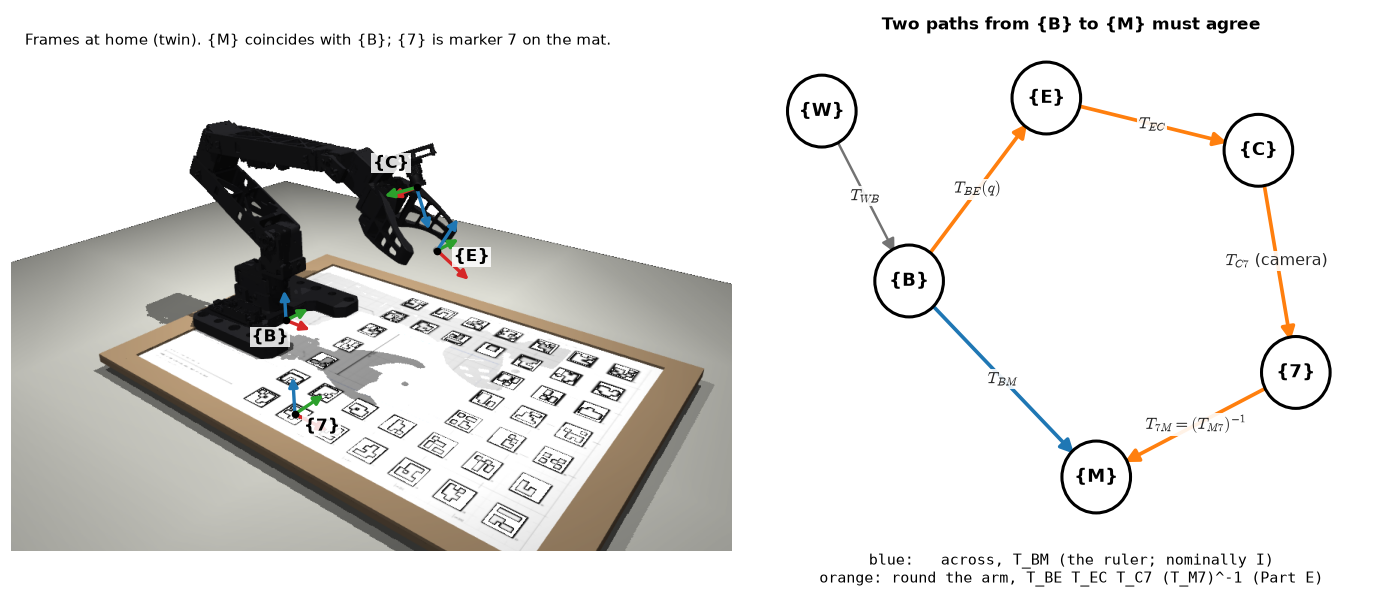

*The work cell as a pose graph. Left: the frames at home in the twin ({M} coincides with {B}; marker 7 is on the mat).
    Right: the two paths from {B} to {M} - straight across, `T_BM` (the ruler, nominally I), or round the arm through what the camera sees,
    `T_BE(q) T_EC T_C7 (T_M7)^-1`. Section 2.7 uses that to measure `T_EC`.*

In [ ]:
# --- worked case: the camera at home, from the kinematics and the design mount -------------------------------------
Q_HOME = np.radians([0, -60, 60, 30])          # home: tool pitched 30 deg down
T_BM = SE3()                                   # nominal: the mat frame is the base frame (2.6 measures it on your bench)
T_BE_home = omx.fkine(Q_HOME).A                # B_T_E(q) from the model
T_BC_home = T_BE_home @ T_EC_CAD.A             # B_T_C = B_T_E E_T_C
print('camera at home, in {B} (mm):', np.round(1e3 * T_BC_home[:3, 3], 1))
print('its optical axis (z_C) in {B}:', np.round(T_BC_home[:3, 2], 3), ' - forward and down')

In [ ]:
# --- Exercise 2.5: what the camera should see of marker 7 from home -------------------------------------------------
K_cam = np.array([[950., 0, 640], [0, 950., 360], [0, 0, 1]])  # the assumed intrinsics (2.6 measures your camera's)
T_C7_pred = ...                    # equation (9), with your inv_T: T_BE_home, T_EC_CAD.A, T_BM.A, T_M7

def in_view(K, p_C, size=(1280, 720)):
    ...                            # True if p_C is in front of the camera (z > 0) and projects inside the image

try_it('C_T_7 predicted', T_C7_pred, (SE3(T_EC_CAD.A).inv() * SE3(T_BE_home).inv() * T_BM * SE3(T_M7)).A, tol=1e-9)
_p = (SE3(T_EC_CAD.A).inv() * SE3(T_BE_home).inv() * T_BM * SE3(T_M7)).t
_uv = (K_cam @ _p)[:2] / _p[2]
try_it('marker 7 in view?', lambda: in_view(K_cam, T_C7_pred[:3, 3]), bool(_p[2] > 0 and 0 <= _uv[0] < 1280 and 0 <= _uv[1] < 720))

<details><summary><b>Hint</b></summary>

Project with $u = f_x X/Z + c_x$, $v = f_y Y/Z + c_y$: in code `(K @ p_C)[:2] / p_C[2]`. From home the camera looks out past the clear
zone (Figure in 2.7), so do not be surprised by the answer.

</details>

**Explore.** The graph drawn in 3D for a sweep of joint 1. Change the joint angles in the loop and run it again.

In [ ]:
# base, mat, and the end effector and (design-mount) camera frames for a sweep of joint 1
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(projection='3d')
SE3().plot(frame='B', ax=ax, color='k', length=0.05)
T_BM.plot(frame='M', ax=ax, color='b', length=0.05)
for q1 in np.radians([-40, -20, 0, 20, 40]):
    T_E = omx.fkine([q1, -1.05, 1.05, 0.52])                 # home pose, base turned
    T_E.plot(frame='E', ax=ax, color='r', length=0.035); (T_E * T_EC_CAD).plot(frame='C', ax=ax, color='m', length=0.035)
ax.set_xlim(-0.1, 0.3); ax.set_ylim(-0.2, 0.2); ax.set_zlim(0, 0.3); plt.show()

<br>

<a id='refs'></a>

### 2.6 On the arm: three reference configurations (arm)
---

From here on you need the arm, or the digital twin (`SIMULATE = True` in the next cell). Connect, re-estimate the camera's intrinsics
from the mat (the focus ring may have moved since last week), and correct the mat's pose if it is visibly off the cross.

In [ ]:
# --- connect to the arm --------------------------------------------------------------------------------------------
# Safe to re-run: an existing connection is closed first, so the COM port is released before it is opened again.
# SIMULATE = True runs the MuJoCo digital twin (omx_mujoco.py) instead of the real arm: same API, a rendered
# wrist camera, and optional hidden model errors so you can test calibration against ground truth.
SIMULATE = False
PORT = 'auto'                  # finds the OpenRB-150 by its USB id; or set it, e.g. 'COM4' (Device Manager) / '/dev/ttyACM0'
# --- which arm are you on today? Read the asset label on the base. Everything you measure is tagged with it,
#     because zero offsets, camera intrinsics and the camera mount are all properties of THIS arm.
ARM_ID = 'OMX-00'            # EDIT every session
if 'arm' in globals():
    try:
        arm.close()
    except Exception as e:
        print('closing the previous connection:', e)
    del arm
if SIMULATE:
    from omx_mujoco import OMXSim, SimCamera
    arm = OMXSim(view=True)    # view=False if no display; set kin_error=..., joint_offsets=... to hide errors
    # Video: arm.record('run.mp4') writes the wrist camera and a scene camera side by side (same size) while the arm
    # moves; arm.stop_recording() when done.
else:
    arm = OMX(PORT)
print('connected:', 'digital twin' if SIMULATE else arm.port_name, '| arm', ARM_ID)

In [ ]:
# --- wrist camera: manual focus, may have been moved since last week -> re-estimate intrinsics NOW from the mat -------
# AUTO = True: the ARM calibrates the camera itself - it moves through 20 views aimed at the mat and takes a frame at
#   each once the joints and the image are static (omx_autocal.py; about 40 s). Torque goes ON and the arm MOVES:
#   keep hands, cables and objects out of the workspace. A live window shows each view.
# AUTO = False: move the camera over the mat by hand instead (torque off, live window, pause at each view).
# Re-run THIS cell on its own to repeat the calibration: the arm connection above is not touched.
# The gripper is left OPEN for all camera work (closed fingers hide the mat); arm.rest() closes it at the end of the lab.
AUTO = True
CAM_INDEX = 'Innomaker'         # the wrist camera by NAME (a laptop's own webcam is usually camera 0); or a number
if globals().get('cam') is not None:
    try:
        cam.close()                # release the camera held by the previous run
    except Exception:
        pass
cam = None
try:
    if SIMULATE:
        cam = SimCamera(arm); raise StopIteration      # twin: exact intrinsics, no per-session calibration needed
    cam = Camera(CAM_INDEX)
    import os
    import omx_camera
    _kb = [p for p in ('camera_K_baseline.npz', os.path.join(omx_camera.HERE, 'camera_K_baseline.npz')) if os.path.exists(p)]
    K0 = np.load(_kb[0])['K'] if _kb else None   # shared staff baseline (scripts/camera_K_baseline.npz): a starting guess only
    if AUTO:
        from omx_autocal import auto_calibrate
        print('Automatic calibration: the arm is about to move. Keep the workspace clear.')
        K, dist, rms = auto_calibrate(arm, cam, ARM_ID, K0=K0, show=True, stages=1, show_mount=False)   # stages=2: + planned views
    else:
        arm.torque(False)
        print('Torque is OFF. Move the camera over the mat by hand (up to 60 s), PAUSING at each view: vary its height between ~90 and 180 mm AND tilt the wrist')
        print('by at least +/-30 degrees (40 is better) - nearly vertical views at one height give a focal length 10-20% wrong.')
        # show=True opens a live window (press q to stop early); still_px keeps a frame only while you hold the camera still
        K, dist, rms = cam.calibrate_from_mat(n_frames=25, seconds=60, K0=K0, save_as=f'camera_K_session_{ARM_ID}.npz',
                                              show=True, still_px=1.5)
    if rms > 1.5: print('WARNING: rms > 1.5 px - check focus and that the mat is flat, then re-run this cell.')
except StopIteration:
    print('simulated wrist camera ready (K exact)')
except Exception as e:
    if cam is not None:
        try: cam.close()
        except Exception: pass
    cam = None; print('camera not available:', e)

In [ ]:
# --- the mat as it is on your bench: nominal, then ruler-corrected (m, deg) - EDIT if the base is visibly off the cross ---
dx, dy, dyaw_deg = 0.0, 0.0, 0.0
T_BM = SE3(dx, dy, 0.0) * SE3.Rz(np.radians(dyaw_deg))
print('T_BM =\n', np.round(T_BM.A, 4))

Lab 3 checks your forward kinematics against three poses where you *know* where the tip is. With torque off, place the gripper tip on
three grid intersections of the mat and record the joint angles and the mat coordinates.

The cell first **closes the gripper**: the model's tool length $l_4$ runs to the closed fingertips, so that is the tip you place. It
then asks you to hold the arm before it switches torque off (at home the arm would drop under gravity), and at the end, with your
hands clear, it switches torque back on and goes home. Type the coordinates in **metres** (`0.20,0.05`, not `200,50`). In the twin
(`SIMULATE = True`) the arm cannot be placed by hand, so the cell puts the tip on three points with the provided IK instead (you write
your own IK in Lab 4).

In [ ]:
import json
TWIN_POINTS = [(0.20, 0.05), (0.15, -0.05), (0.25, 0.00)]      # grid intersections (m) used in the twin

def ask_xy(prompt):
    """Mat coordinates typed as x,y in metres; asks again for anything off the mat (e.g. millimetres)."""
    while True:
        try:
            x, y = [float(v) for v in input(prompt).split(',')]
            if -0.06 <= x <= 0.36 and abs(y) <= 0.1485:
                return x, y
            print('  that is off the mat: type metres, e.g. 0.20,0.05 (the mat spans x -0.06..0.36, y -0.15..0.15)')
        except ValueError:
            print('  type two numbers separated by a comma, e.g. 0.20,0.05')

refs = []
if SIMULATE:
    arm.torque(True); arm.set_profile(40, 10)
    for x, y in TWIN_POINTS:
        arm.move_q(omx_ik([x, y, 0.0], np.pi / 2, elbow='any'), wait=True)
        refs.append(dict(q=arm.read_q().tolist(), p_M=[x, y, 0.0], p_B=(T_BM * [x, y, 0.0]).tolist()))
        print(f'  tip on ({x}, {y}): q (deg) =', np.round(np.degrees(arm.read_q()), 1))
    arm.home(wait=True)
else:
    arm.set_gripper('closed', wait=True)       # l4 runs to the closed fingertips: that is the tip you place
    input('Hold the arm with one hand, then press Enter: torque goes OFF...')
    arm.torque(False)
    for k in range(3):
        input(f'Place the tip on grid point {k+1} and press Enter...')
        q = arm.read_q()
        x, y = ask_xy('  mat coordinates x,y in metres (e.g. 0.20,0.05): ')
        refs.append(dict(q=q.tolist(), p_M=[x, y, 0.0], p_B=(T_BM * [x, y, 0.0]).tolist()))
        print('  q (deg) =', np.round(np.degrees(q), 1))
    input('Leave the tip on the mat, take your hands away, then press Enter: torque goes ON and the arm goes home...')
    arm.torque(True); arm.set_profile(40, 10); arm.home(wait=True)
json.dump(dict(T_BM=T_BM.A.tolist(), refs=refs), open('lab2_refs.json', 'w'), indent=1)
print('saved lab2_refs.json')

<br>

<a id='mount'></a>

### 2.7 On the arm: the camera measures its own mount (arm)
---

`cam.mat_pose()` solves all the markers it can see at once and returns ${}^{C}\mathbf{T}_{M}$, the mat's pose in the camera frame.
Chaining through the arm gives the mat in the base frame, ${}^{B}\mathbf{T}_{M} = {}^{B}\mathbf{T}_{E}(q)\,{}^{E}\mathbf{T}_{C}\,{}^{C}\mathbf{T}_{M}$,
which should be close to the identity. Turned round, with the mat pose known, each view **measures the camera mount**:

$$ {}^{E}\mathbf{T}_{C} = {}^{B}\mathbf{T}_{E}(q)^{-1}\,{}^{B}\mathbf{T}_{M}\,{}^{C}\mathbf{T}_{M}^{-1} \qquad (10) $$

`T_EC_CAD` is the design value. The camera on *your* arm sits a little differently in its clamp, and a few millimetres or a degree at
the camera becomes several millimetres on the mat.

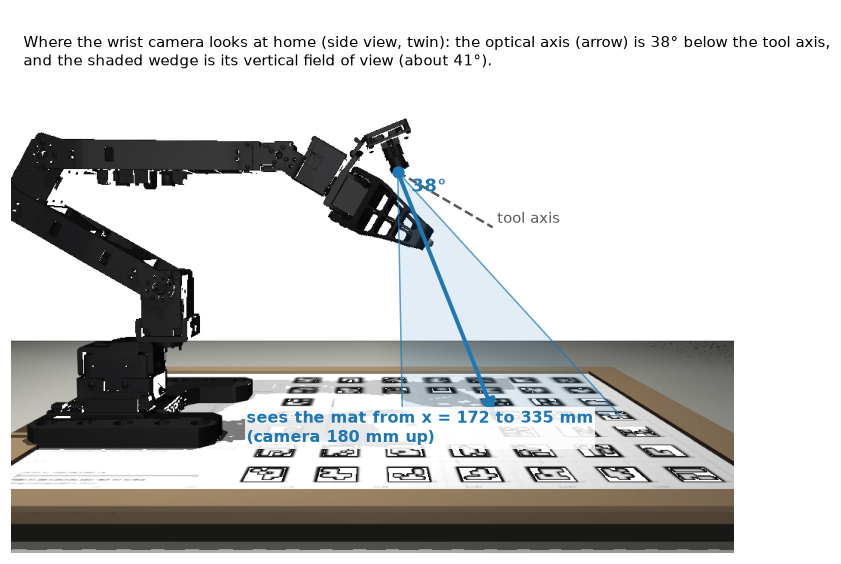

*Where the wrist camera looks at home (side view, twin). The camera sits on its bracket above the gripper; its
    optical axis is 38 degrees below the tool axis (the design mount, from the ROBOTIS CAD) and, from home, it sees the mat from x = 172 to
    335 mm. The camera on *your* arm will sit a little differently: this section measures it.*

### Task 3 — Chaining a camera measurement to the base frame - and measuring the camera mount
The camera gives `T_CM`; the kinematics gives `T_BE(q)`; `T_EC` is the camera mount. Write `chain_T_BM` that returns the estimate of the
mat pose in the base frame (the long way round the pose graph). A helper below the task, `spread(Ts)`, reports how far several such
estimates disagree.

`T_EC_CAD` is the design value of the camera mount; the camera on your arm sits a little differently in its clamp. Turn the chain round:
with the mat pose `T_BM` known (nominally the identity: the mat frame is the base frame), each view gives the mount, `T_EC = T_BE^-1 T_BM T_CM^-1`. Write `mount_from_views(T_BEs, T_CMs, T_BM)` that
returns the average over the views as a 4x4: the mean translation, and the mean of the rotation matrices projected back onto a rotation
with the SVD (`U, _, Vt = svd(R_mean)`, `R = U Vt`). Section 2.7 measures your arm's mount with it; every later lab re-measures it at the start.

In [ ]:
def chain_T_BM(T_BE, T_EC, T_CM):
    """All 4x4 NumPy arrays. Returns T_BM."""
    # TODO: write your implementation here
    raise NotImplementedError

def mount_from_views(T_BEs, T_CMs, T_BM=np.eye(4)):
    """Lists of 4x4 arrays (one pair per view) -> 4x4 camera mount T_EC averaged over the views."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
try:
    _Tm23 = np.array([[0.0, -0.615661475326, 0.788010753607, -0.0459], [-1.0, 0.0, 0.0, 0.0], [0.0, -0.788010753607, -0.615661475326, 0.0332], [0.0, 0.0, 0.0, 1.0]])
    _BE23 = [small_T(np.array(v)) for v in ([0.1, 0.9, -0.2, 0.2, 0.0, 0.15], [-0.3, 1.1, 0.4, 0.18, -0.05, 0.2], [0.5, 0.7, 0.1, 0.22, 0.06, 0.12])]
except NotImplementedError:
    print('  (test fixtures need your earlier function first)')
check('chain closes to identity when T_CM = inv(T_EC)', lambda: chain_T_BM(np.eye(4), T_EC_CAD.A, np.linalg.inv(T_EC_CAD.A)), '0b5daec8bb', decimals=6)
check('mount recovered exactly from three views (T_BM = I)', lambda: mount_from_views(_BE23, [np.linalg.inv(T @ _Tm23) for T in _BE23]), 'e482167504', decimals=6)
check('two views with +/-2 deg of roll noise average to the true mount', lambda: mount_from_views(_BE23[:2], [np.linalg.inv(T @ _Tm23 @ small_T(np.array([s * 0.035, 0, 0, 0, 0, 0]))) for T, s in zip(_BE23[:2], (1, -1))]), 'e3ac6f9af6', decimals=5)

The next cell checks the focus and opens a **live view** of the wrist camera: the markers it finds, the mat's axes and the
reprojection error. The window may open *behind* this one - look for it on the taskbar. The notebook waits until you press **q** in
that window.

In [ ]:
def spread(Ts):
    """Given: list of 4x4 arrays -> [mean, max] deviation (mm) of their translations about the mean."""
    t = np.array([T[:3, 3] for T in Ts]); d = 1e3 * np.linalg.norm(t - t.mean(0), axis=1)
    return np.array([d.mean(), d.max()])

if cam is None: raise RuntimeError('no camera: re-run the wrist-camera cell in 2.6 (check the USB cable and CAM_INDEX)')
if not SIMULATE:
    sharp, n = cam.focus_check(); print(f'sharpness {sharp:.0f}, markers seen {n}  (soft image or < 4 markers at 180 mm -> ask a demonstrator to check the focus ring)')
    print('live view open (it may be behind this window): press q in it to continue')
    cam.show()          # live view: markers, axes, reprojection error. Press q in the window to stop.

The arm now visits a few poses that see the mat and chains each view, equation (10). Two numbers come out: your measured mount, and
the **spread** of the ${}^{B}\mathbf{T}_{M}$ estimates, each view's long way round the pose graph, with your mount and with the
design one. The views should agree, and with your mount they should agree better. In the twin, whose kinematics is exact, the spread
with the measured mount is under 1 mm. On a real arm expect several millimetres (8 mm mean with the measured mount, 32 mm with the design one, on the first arm): ${}^{B}\mathbf{T}_{E}(q)$
comes from the *nominal* model, and the servos' zero offsets and the real link lengths are not calibrated yet (Lab 9 does that).
Tens of millimetres means something is wrong: look for a view that saw only a few markers, or a camera image taken before the arm
stopped (the webcam hands back one image from before each move; `cam.read()` throws it away for you).

In [ ]:
# --- the views: the arm visits poses that see the mat, the camera measures C_T_M at each -------------------------------
from omx_autocal import bootstrap_views       # poses that see the mat for any mount within ~10 deg of the design mount
if cam is None: raise RuntimeError('no camera: re-run the wrist-camera cell in 2.6 (check the USB cable and CAM_INDEX)')
arm.torque(True); arm.set_profile(40, 10)
if not SIMULATE: arm.set_gripper('open', wait=True)    # closed fingers hide the mat
T_BEs, T_CMs = [], []
for q in bootstrap_views()[::3]:
    arm.move_q(q, wait=True); time.sleep(0.5)
    T_CM, n = cam.mat_pose_avg(5)
    if T_CM is None: print('no markers seen at', np.round(np.degrees(q))); continue
    T_BEs.append(omx.fkine(arm.read_q()).A); T_CMs.append(T_CM.A)
arm.home(wait=True)
T_EC = SE3(mount_from_views(T_BEs, T_CMs, T_BM.A), check=False)          # YOUR measured mount, equation (10)
spread_meas = spread([chain_T_BM(Tbe, T_EC.A, Tcm) for Tbe, Tcm in zip(T_BEs, T_CMs)])
spread_cad = spread([chain_T_BM(Tbe, T_EC_CAD.A, Tcm) for Tbe, Tcm in zip(T_BEs, T_CMs)])
print(f'{len(T_BEs)} views | T_BM spread [mean, max]: measured mount {np.round(spread_meas, 1)} mm, design mount {np.round(spread_cad, 1)} mm')
if spread_meas[0] > spread_cad[0] + 1.0: print('  the measured mount fits the views WORSE than the design one: check chain_T_BM and mount_from_views')
import json; json.dump(dict(arm=ARM_ID, T_EC=T_EC.A.tolist(), views=len(T_BEs)), open(f'lab2_mount_{ARM_ID}.json', 'w'), indent=1)

In [ ]:
# --- Exercise 2.7: how far is your mount from the design? -----------------------------------------------------------
axis_angle_deg = ...               # angle between the two optical axes (the z columns of T_EC.A and T_EC_CAD.A), degrees
offset_mm = ...                    # distance between the two camera origins, mm
try_it('angle between the optical axes', axis_angle_deg, np.degrees(np.arccos(np.clip((T_EC_CAD.inv() * T_EC).R[2, 2], -1, 1))), tol=1e-6)
try_it('distance between the camera origins', offset_mm, 1e3 * np.linalg.norm((T_EC_CAD.inv() * T_EC).t), tol=1e-6)

<details><summary><b>Hint</b></summary>

The angle between two unit vectors comes from their dot product: `np.degrees(np.arccos(a @ b))` (clip to [-1, 1] first). The optical
axis is the third column of each mount's rotation, `T.A[:3, 2]`.

</details>

**(stretch, bench only) What covering markers does to the measurement.** The arm is at home, looking at the mat. Run the first cell
with the whole mat in view; then cover half the markers the camera sees with a sheet of paper, and run the second.

In [ ]:
# --- Exercise 2.7b, step 1: the whole mat in view ----------------------------------------------------------------------
if cam is None: raise RuntimeError('no camera: re-run the wrist-camera cell in 2.6')
T_CM_all, n_all = cam.mat_pose_avg(5) if not SIMULATE else (SE3(), 0)
print('measured C_T_M with the whole mat in view - now cover half the markers and run the next cell')

In [ ]:
# --- Exercise 2.7b, step 2: half the markers covered ---------------------------------------------------------------
T_CM_half, n_half = cam.mat_pose_avg(5) if not SIMULATE else (SE3(), 0)
shift_mm = ...                     # how far the mat's origin moved between the two measurements, mm
turn_deg = ...                     # how far it turned, degrees (the angle of the relative rotation)
try_it('shift (mm)', shift_mm, 1e3 * np.linalg.norm((T_CM_all.inv() * T_CM_half).t), tol=1e-6)
try_it('turn (deg)', turn_deg, np.degrees((T_CM_all.inv() * T_CM_half).angvec()[0]), tol=1e-6)

**What does a degree cost?** Before you run the next cell, guess: if the mat is turned 1 degree about the base axis, how far does its far
corner, 360 mm out and 148.5 mm to the side, move? Write your guess in millimetres, then compute it.

In [ ]:
# --- Exercise 2.7c: what 1 degree of mat yaw costs at the far corner of the mat -------------------------------------------
my_guess_mm = ...                  # your guess first
far_corner = np.array([0.360, 0.1485, 0.0])     # the mat's far corner in {M} (m): 360 mm forward, 148.5 mm to the side
error_mm = ...                     # how far that corner moves if the mat is turned 1 deg about the base axis, mm
try_it('error at the far corner (mm)', error_mm, 1e3 * np.linalg.norm((SE3.Rz(1, 'deg') * far_corner).ravel() - far_corner), tol=1e-3)
if my_guess_mm is not ... and error_mm is not ...: print(f'you guessed {my_guess_mm} mm; it is {error_mm:.1f} mm')

In [ ]:
# --- checkpoint: show this line to a demonstrator ------------------------------------------------------------------
print(f'ARM {ARM_ID} | mount {np.degrees(mount_tilt(T_EC)):.1f} deg below the tool (design {np.degrees(mount_tilt(T_EC_CAD)):.0f}), '
      f'{1e3 * np.linalg.norm(T_EC.A[:3, 3] - T_EC_CAD.A[:3, 3]):.1f} mm from the design origin | T_BM spread: measured '
      f'{spread_meas[0]:.1f} mm, design {spread_cad[0]:.1f} mm')

<br>

<a id='sm'></a>

### 2.8 The whole lab in spatialmath (desk)
---

What you built by hand, one line each with the toolbox - the way you will usually write it from Lab 3 on. `SO3` and `SE3` objects
keep the matrix valid, `*` composes (and applies a pose to a point), `.inv()` is equation (8), `.rpy()` is equation (6), and `.R`
and `.t` give the blocks. Keep this cell as a reference for the assignment.

In [ ]:
R_AC = SO3.Rz(90, 'deg') * SO3.Ry(-90, 'deg')                             # 2.1  rotations chain; inner letters cancel
print('2.1  one point, three frames:', (R_AC * [0, -1, -1]).ravel())
print('2.2  x_b, fixed then body axes:', (SO3.Ry(90, 'deg') * SO3.Rx(90, 'deg')).A[:, 0], (SO3.Rx(90, 'deg') * SO3.Ry(90, 'deg')).A[:, 0])
print('2.3  roll-pitch-yaw round trip (deg):', np.degrees(SO3.RPY(np.radians([20, 30, 40]), order='zyx').rpy(order='zyx')))
T_BM_laid = SE3(0.010, 0, 0) * SE3.Rz(5, 'deg')                           # 2.4  a pose: translate, then rotate
print('2.4  marker 24 on the laid mat (mm):', np.round(1e3 * (T_BM_laid * SE3(0.25, 0.08, 0)).t, 1))
T_BC = omx.fkine(Q_HOME) * T_EC_CAD                                       # 2.5  base -> tool -> camera
print('2.5  camera at home (mm):', np.round(1e3 * T_BC.t, 1))
print('2.7  your mount, E_T_C (the design value until 2.7 has run):'); print(T_EC)

## Before you leave
1. Park the arm (`arm.rest()`: the folded rest pose, where it stays put with torque off), then `arm.torque(False)` and `arm.close()`.
   Never switch torque off at home or mid-task: the arm drops under gravity.
2. Switch off the bench power supply and tidy cables.
3. Show your checkpoint output to a demonstrator for sign-off.
4. Commit this notebook and any data files to your own LABS repository and **push** (Sync Changes): later labs read them. The assessment repository (issued in week 6) starts fresh; copy across any code you want to reuse.

In [ ]:
arm.set_profile(40, 10); arm.rest(wait=True)     # folded rest pose: stable with torque off
arm.torque(False)
arm.close()
if globals().get('cam') is not None: cam.close()